# ROAD TRAFFIC CRASH PREDICTION

## Project Overview 

Road traffic accidents are a major public safety concern, resulting in loss of lives, injuries, property damage, and economic losses.
Understanding factors associated with road crashes can help authorities identify patterns and develop more effective road safety interventions.
This project aims to develop a machine learning model that predicts road crash severity using historical crash-related data.

## Business Understanding

Road crashes remain a major public safety concern, resulting in fatalities, injuries, and property damage. Understanding the factors associated with crash severity is essential in developing effective road safety strategies. This project seeks to address the challenge by analysing historical road crash records and developing a machine learning model capable of classifying crashes according to their severity. The resulting insights could help identify high-risk conditions and support authorities in making informed decisions towards improving road safety.

## Data Understanding

The dataset was sourced from [World Bank Microdata Library](https://microdata.worldbank.org/index.php/catalog/6249)

## Data Understanding

**Source of Data:**

The dataset used in this project is a processed road crash dataset provided in CSV format (`processed_crash_data.csv`).

**Description of Data:**

The dataset contains 25,252 records and 17 features describing different characteristics of road crashes. The target variable is `severity_index`, which will be used to train the machine learning model.

**Feature Description:**

| Feature | Description |
|---|---|
| `n_crash_reports` | Represents the number of crash reports associated with a record. |
| `contains_fatality_words` | Indicates whether the crash report contains words associated with fatalities (1 = Yes, 0 = No). |
| `contains_pedestrian_words` | Indicates whether the crash report contains pedestrian-related words (1 = Yes, 0 = No). |
| `year` | The year in which the crash occurred. |
| `day_of_week` | The name of the day on which the crash occurred, such as Monday or Tuesday. |
| `hour` | The hour of the day when the crash occurred. |
| `day` | The day of the month when the crash occurred. |
| `weekday` | A numerical representation of the day of the week. |
| `month` | The month in which the crash occurred, represented numerically. |
| `is_weekend` | Indicates whether the crash occurred during a weekend (1 = Yes, 0 = No). |
| `day_part` | Classifies the time of occurrence into different periods of the day, such as morning, afternoon, evening, and night. |
| `distance_to_nairobi` | Represents the geographical distance of the crash location from Nairobi. |
| `contains_vehicle_words` | Indicates whether the crash report contains vehicle-related words (1 = Yes, 0 = No). |
| `severity_index` | The target variable representing the severity category assigned to each crash record. |
| `local_crash_density` | Represents the concentration or frequency of crashes within a particular locality. |
| `season` | Classifies the period of occurrence according to seasonal categories, such as dry, rainy, or transitional. |
| `fatality_mention_ratio` | Represents the proportion of fatality-related mentions associated with a crash record. |

The dataset contains both numerical and categorical variables, making it suitable for classification analysis. The `severity_index` feature will serve as the dependent variable, while the remaining features will initially be considered independent variables, subject to further investigation and feature selection.

## 1. Importing Libraries

These libraries help us load and inspect the data, perform calculations, and create charts.

In [55]:
# Import the libraries used for working with data and creating visualizations.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Cleaning and Inspection

Loading and inspecting the dataframe

## 2. Loading the Dataset

Load the processed crash dataset that will be used throughout the notebook.

In [56]:
# Load the processed crash dataset and display its number of rows and columns.

df = pd.read_csv('processed_crash_data.csv')
print("Original shape:", df.shape)

Original shape: (25252, 17)


### Viewing the First Records

A quick preview helps us understand how the data is arranged.

In [57]:
# Display the first 10 rows to get a quick look at the dataset.

df.head(10)

,n_crash_reports,contains_fatality_words,contains_pedestrian_words,year,day_of_week,hour,day,weekday,month,is_weekend,day_part,distance_to_nairobi,contains_vehicle_words,severity_index,local_crash_density,season,fatality_mention_ratio
0,1,0,0,2018.0,Wednesday,20.0,6.0,2.0,6.0,0,evening,7.165499,0,0,3303,dry,0.054249
1,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,56.743166,0,1,1,transitional,0.062719
2,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,27.398293,0,0,481,transitional,0.062719
3,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,60.469275,0,0,5,transitional,0.062719
4,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,4.287275,0,1,7019,transitional,0.062719
5,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,8.644064,0,0,1767,transitional,0.062719
6,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,14.147602,0,1,978,transitional,0.062719
7,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,9.221275,0,0,729,transitional,0.062719
8,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,2.922511,0,0,7267,transitional,0.062719
9,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,10.174603,0,0,1987,transitional,0.062719


### Summary Statistics

This gives a statistical overview of the numerical columns.

In [58]:
# Show summary statistics for numerical columns, such as the mean and minimum.

df.describe()

,n_crash_reports,contains_fatality_words,contains_pedestrian_words,year,hour,day,weekday,month,is_weekend,distance_to_nairobi,contains_vehicle_words,severity_index,local_crash_density,fatality_mention_ratio
count,25252.0,25252.000000,25252.0,10259.000000,10259.000000,10259.000000,10259.000000,10259.000000,25252.000000,25252.000000,25252.0,25252.000000,25252.000000,25252.000000
mean,1.0,0.060510,0.0,2017.082757,13.134321,6.618871,3.015888,6.508237,0.116387,11.786159,0.0,0.060510,3954.517108,0.060510
std,0.0,0.238434,0.0,2.730444,5.542625,3.451835,1.993810,3.446695,0.320695,15.133355,0.0,0.238434,2942.071604,0.003108
min,1.0,0.000000,0.0,2012.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.033808,0.0,0.000000,0.000000,0.054249
25%,1.0,0.000000,0.0,2015.000000,8.000000,4.000000,1.000000,3.000000,0.000000,3.761964,0.0,0.000000,1035.000000,0.057740
50%,1.0,0.000000,0.0,2017.000000,13.000000,7.000000,3.000000,7.000000,0.000000,7.320735,0.0,0.000000,3401.500000,0.062719
75%,1.0,0.000000,0.0,2019.000000,18.000000,10.000000,5.000000,9.000000,0.000000,13.916086,0.0,0.000000,7053.000000,0.062719
max,1.0,1.000000,0.0,2023.000000,23.000000,12.000000,6.000000,12.000000,1.000000,224.268715,0.0,1.000000,8936.000000,0.062719


### Dataset Structure

Check the data types and dimensions so we know what information the dataset contains.

In [59]:
# Display column names, data types, non-null counts, and the dataset dimensions.

df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 25252 entries, 0 to 25251
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   n_crash_reports            25252 non-null  int64  
 1   contains_fatality_words    25252 non-null  int64  
 2   contains_pedestrian_words  25252 non-null  int64  
 3   year                       10259 non-null  float64
 4   day_of_week                10259 non-null  str    
 5   hour                       10259 non-null  float64
 6   day                        10259 non-null  float64
 7   weekday                    10259 non-null  float64
 8   month                      10259 non-null  float64
 9   is_weekend                 25252 non-null  int64  
 10  day_part                   25252 non-null  str    
 11  distance_to_nairobi        25252 non-null  float64
 12  contains_vehicle_words     25252 non-null  int64  
 13  severity_index             25252 non-null  int64  
 14  l

(25252, 17)

### Checking for Missing Values

Identify columns with missing information before continuing with the analysis.

In [60]:
# Count missing values in each column and show only columns that contain missing data.

missing_values = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': (df.isnull().mean() * 100).round(2)
})

missing_values[missing_values['Missing Values'] > 0]

,Missing Values,Percentage
year,14993,59.37
day_of_week,14993,59.37
hour,14993,59.37
day,14993,59.37
weekday,14993,59.37
month,14993,59.37


### Removing Duplicate Records

Duplicate rows can affect analysis, so we check for and remove exact duplicates.

In [61]:
# Identify duplicate rows, remove them, and check the dataset size afterwards.

print("Duplicate records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Duplicate records: 9374
Shape after removing duplicates: (15878, 17)


### Removing Constant Columns

Columns that contain the same value in every row do not help a model learn patterns.

In [62]:
# Find columns with only one unique value and remove them, except for the target column.

constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
    and col != "severity_index"
]

df.drop(columns=constant_columns, inplace=True)

print("Removed columns:", constant_columns)

Removed columns: ['n_crash_reports', 'contains_pedestrian_words', 'contains_vehicle_words']


### Identifying Missing Date and Time Information

Create a flag to identify records where one or more selected date or time fields are missing.

In [63]:
# Create an indicator showing whether any of the selected date or time fields are missing in each row.

temporal_columns = [
    "year", "day_of_week", "hour",
    "day", "weekday", "month"
]

df["temporal_info_missing"] = (
    df[temporal_columns].isna().any(axis=1)
).astype(int)

### Checking Missing Values After Cleaning

Review the remaining missing values. Some may be handled later during model preprocessing.

In [64]:
# Check the number of missing values remaining in every column after cleaning.

print(df.isnull().sum())

contains_fatality_words       0
year                       5619
day_of_week                5619
hour                       5619
day                        5619
weekday                    5619
month                      5619
is_weekend                    0
day_part                      0
distance_to_nairobi           0
severity_index                0
local_crash_density           0
season                        0
fatality_mention_ratio        0
temporal_info_missing         0
dtype: int64


### Saving the Cleaned Dataset

Save a separate copy of the cleaned data so it can be reused.

In [65]:
# Save the cleaned dataset to a new CSV file and display its updated dimensions.

df.to_csv("cleaned_crash_data_with_temporal.csv", index=False)
print("Revised dataset shape:", df.shape)

Revised dataset shape: (15878, 15)


## 3. Exploratory Data Analysis (EDA)

EDA helps us explore patterns in the crash records before building a model.

In [66]:
# Count how many records belong to each crash severity class.

df["severity_index"].value_counts()

severity_index
0    14563
1     1315
Name: count, dtype: int64

### Crash Severity Percentages

Percentages make it easier to compare the share of each severity class.

In [67]:
# Calculate the percentage of records in each crash severity class.

severity_percentage = (
    df["severity_index"].value_counts(normalize=True) * 100
)

severity_percentage

severity_index
0    91.718101
1     8.281899
Name: proportion, dtype: float64

### Crash Records by Category

Compare crash counts across day of the week, day part, and season.

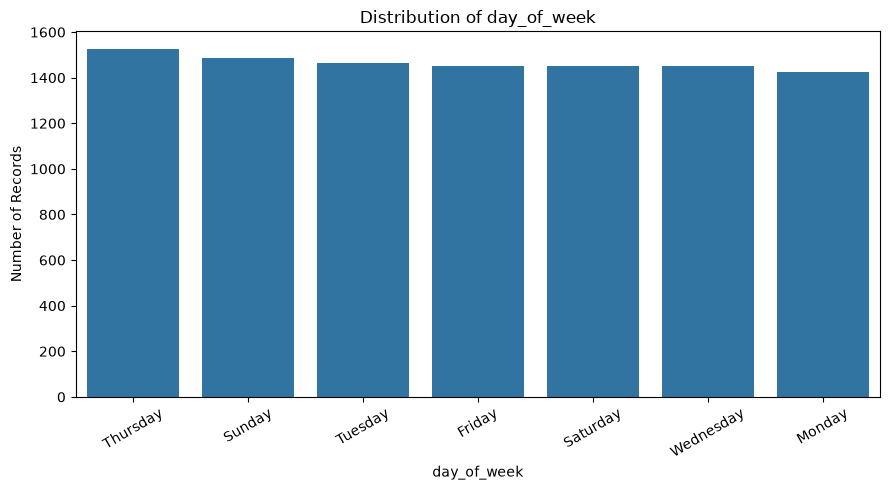

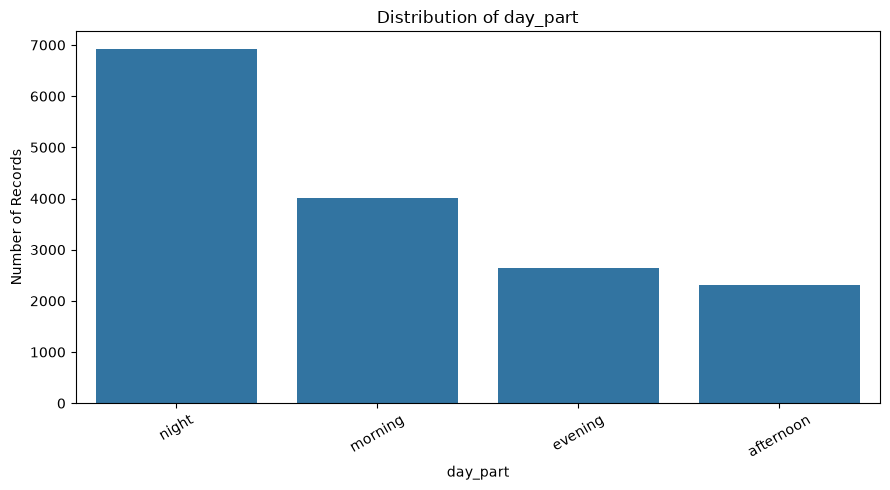

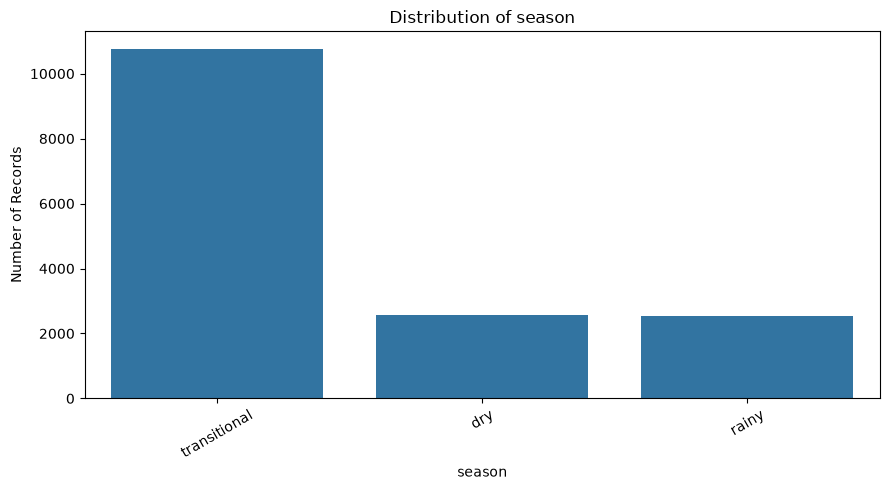

In [68]:
# Draw a count plot for each selected category to compare how often its values occur.

categorical_columns = [
    "day_of_week",
    "day_part",
    "season"
]

for column in categorical_columns:

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x=column,
        order=df[column].value_counts().index
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of Records")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

### Crash Records by Hour

Explore whether some hours have more recorded crashes than others.

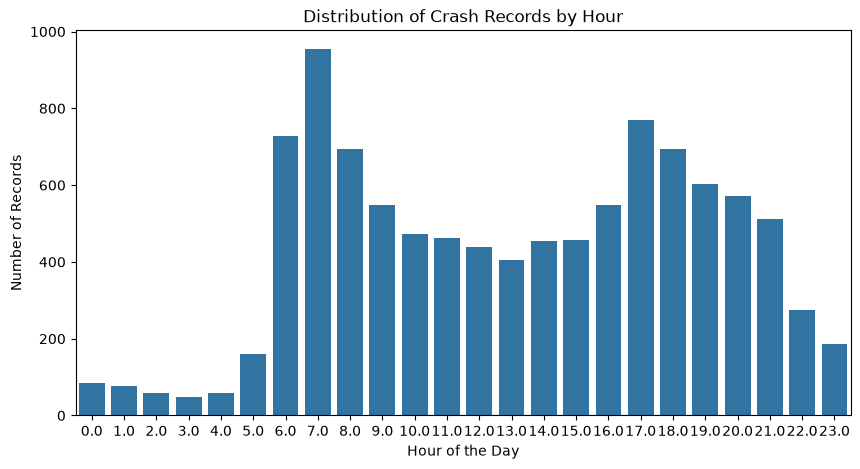

In [69]:
# Show how crash records are distributed across the hours of the day.

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="hour",
    order=sorted(df["hour"].dropna().unique())
)

plt.title("Distribution of Crash Records by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Records")
plt.show()

### Crash Records by Month

Compare the number of recorded crashes across the months.

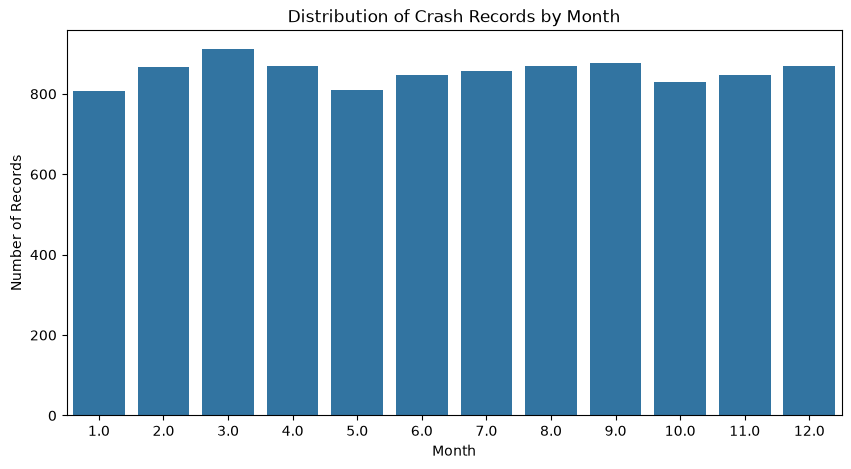

In [70]:
# Show how crash records are distributed across the months of the year.

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="month",
    order=sorted(df["month"].dropna().unique())
)

plt.title("Distribution of Crash Records by Month")
plt.xlabel("Month")
plt.ylabel("Number of Records")
plt.show()

### Temporal Analysis: Day of the Week

This section examines how recorded crashes are distributed across the days of the week. Only records with an observed `day_of_week` value are included, so missing timestamps are not silently assigned to a day.

In [ ]:
# Standardise weekday labels and count recorded crashes in calendar order.

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

temporal_day = df.dropna(subset=["day_of_week"]).copy()
temporal_day["day_of_week"] = (
    temporal_day["day_of_week"].astype("string").str.strip().str.title()
)

day_counts = (
    temporal_day["day_of_week"]
    .value_counts()
    .reindex(day_order, fill_value=0)
)

plt.figure(figsize=(11, 5))
sns.barplot(x=day_counts.index, y=day_counts.values)
plt.title("Recorded Road Crashes by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Records with an observed weekday:", int(day_counts.sum()))
print("Highest recorded weekday:", day_counts.idxmax(), "-", int(day_counts.max()))
print("Lowest recorded weekday:", day_counts.idxmin(), "-", int(day_counts.min()))

### Temporal Analysis: Weekdays vs Weekends

Compare the recorded crash counts for weekdays and weekends. This is a count comparison, not a crash-risk rate: traffic exposure (such as the number of journeys) is not available in this dataset.

In [ ]:
# Compare weekday and weekend counts using the existing is_weekend feature.

weekend_labels = df["is_weekend"].map({
    0: "Weekday", 1: "Weekend",
    "0": "Weekday", "1": "Weekend",
    False: "Weekday", True: "Weekend"
})

weekend_counts = (
    weekend_labels.dropna()
    .value_counts()
    .reindex(["Weekday", "Weekend"], fill_value=0)
)

plt.figure(figsize=(8, 5))
sns.barplot(x=weekend_counts.index, y=weekend_counts.values)
plt.title("Recorded Road Crashes: Weekdays vs Weekends")
plt.xlabel("Day Category")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

print(weekend_counts)
print("Total records included:", int(weekend_counts.sum()))

### Temporal Analysis: Hourly Distribution

Examine the distribution across all 24 hours. The chart is ordered chronologically so peaks and quieter periods can be compared more easily.

In [ ]:
# Count observed crash times by hour (0 to 23).

hour_values = pd.to_numeric(df["hour"], errors="coerce")
hour_counts = (
    hour_values.dropna().astype(int)
    .value_counts()
    .reindex(range(24), fill_value=0)
)

plt.figure(figsize=(13, 5))
sns.lineplot(x=hour_counts.index, y=hour_counts.values, marker="o")
plt.title("Recorded Road Crashes Across the 24 Hours")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Records")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Busiest observed hour:", int(hour_counts.idxmax()),
      "-", int(hour_counts.max()), "records")
print("Records with an observed hour:", int(hour_counts.sum()))

### Temporal Analysis: Day of Week and Hour

The heatmap combines two time dimensions. Darker cells indicate more records in that weekday-hour combination. It can reveal specific periods that deserve further investigation.

In [ ]:
# Build a weekday-by-hour frequency table using rows with both values observed.

day_hour = df.dropna(subset=["day_of_week", "hour"]).copy()
day_hour["day_of_week"] = (
    day_hour["day_of_week"].astype("string").str.strip().str.title()
)
day_hour["hour"] = pd.to_numeric(day_hour["hour"], errors="coerce")
day_hour = day_hour.dropna(subset=["hour"])
day_hour["hour"] = day_hour["hour"].astype(int)

day_hour_table = pd.crosstab(
    day_hour["day_of_week"],
    day_hour["hour"]
).reindex(index=day_order, columns=range(24), fill_value=0)

plt.figure(figsize=(16, 6))
sns.heatmap(
    day_hour_table,
    cmap="YlOrRd",
    linewidths=0.25,
    cbar_kws={"label": "Number of Records"}
)
plt.title("Recorded Road Crashes by Weekday and Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Day of the Week")
plt.tight_layout()
plt.show()

print("Records included in weekday-hour heatmap:", int(day_hour_table.to_numpy().sum()))
print("Highest weekday-hour combination:")
print(day_hour_table.stack().idxmax(), "-", int(day_hour_table.stack().max()), "records")

### Temporal Analysis: Monthly Distribution

Compare recorded crashes across calendar months in chronological order. Month values are treated as numeric month numbers (1 = January through 12 = December).

In [ ]:
# Count observed crashes by month in calendar order.

month_values = pd.to_numeric(df["month"], errors="coerce")
month_counts = (
    month_values.dropna().astype(int)
    .value_counts()
    .reindex(range(1, 13), fill_value=0)
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(12, 5))
sns.barplot(x=month_names, y=month_counts.values)
plt.title("Recorded Road Crashes by Month")
plt.xlabel("Month")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

print("Highest recorded month:", month_names[int(month_counts.values.argmax())],
      "-", int(month_counts.max()), "records")
print("Records with an observed month:", int(month_counts.sum()))

### Temporal Analysis: Class 1 Share by Weekday

Crash frequency and severity composition are different questions. This chart compares the percentage of observed records labelled Class 1 within each weekday. It does not estimate the probability of a crash occurring, and it should be interpreted with the small Class 1 sample in mind.

In [ ]:
# Calculate the within-day percentage of records labelled severity class 1.

severity_day = df.dropna(
    subset=["day_of_week", "severity_index"]
).copy()
severity_day["day_of_week"] = (
    severity_day["day_of_week"].astype("string").str.strip().str.title()
)

class1_share = (
    severity_day.assign(is_class1=(severity_day["severity_index"] == 1).astype(int))
    .groupby("day_of_week")["is_class1"]
    .mean()
    .reindex(day_order)
    .mul(100)
)

plt.figure(figsize=(11, 5))
sns.barplot(x=class1_share.index, y=class1_share.values)
plt.title("Class 1 Share of Recorded Crashes by Weekday")
plt.xlabel("Day of the Week")
plt.ylabel("Class 1 Records (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Class 1 share by weekday (%):")
print(class1_share.round(2))
print("Records included:", len(severity_day))

### Numerical Feature Distributions

Histograms show how values in the numerical features are spread out.

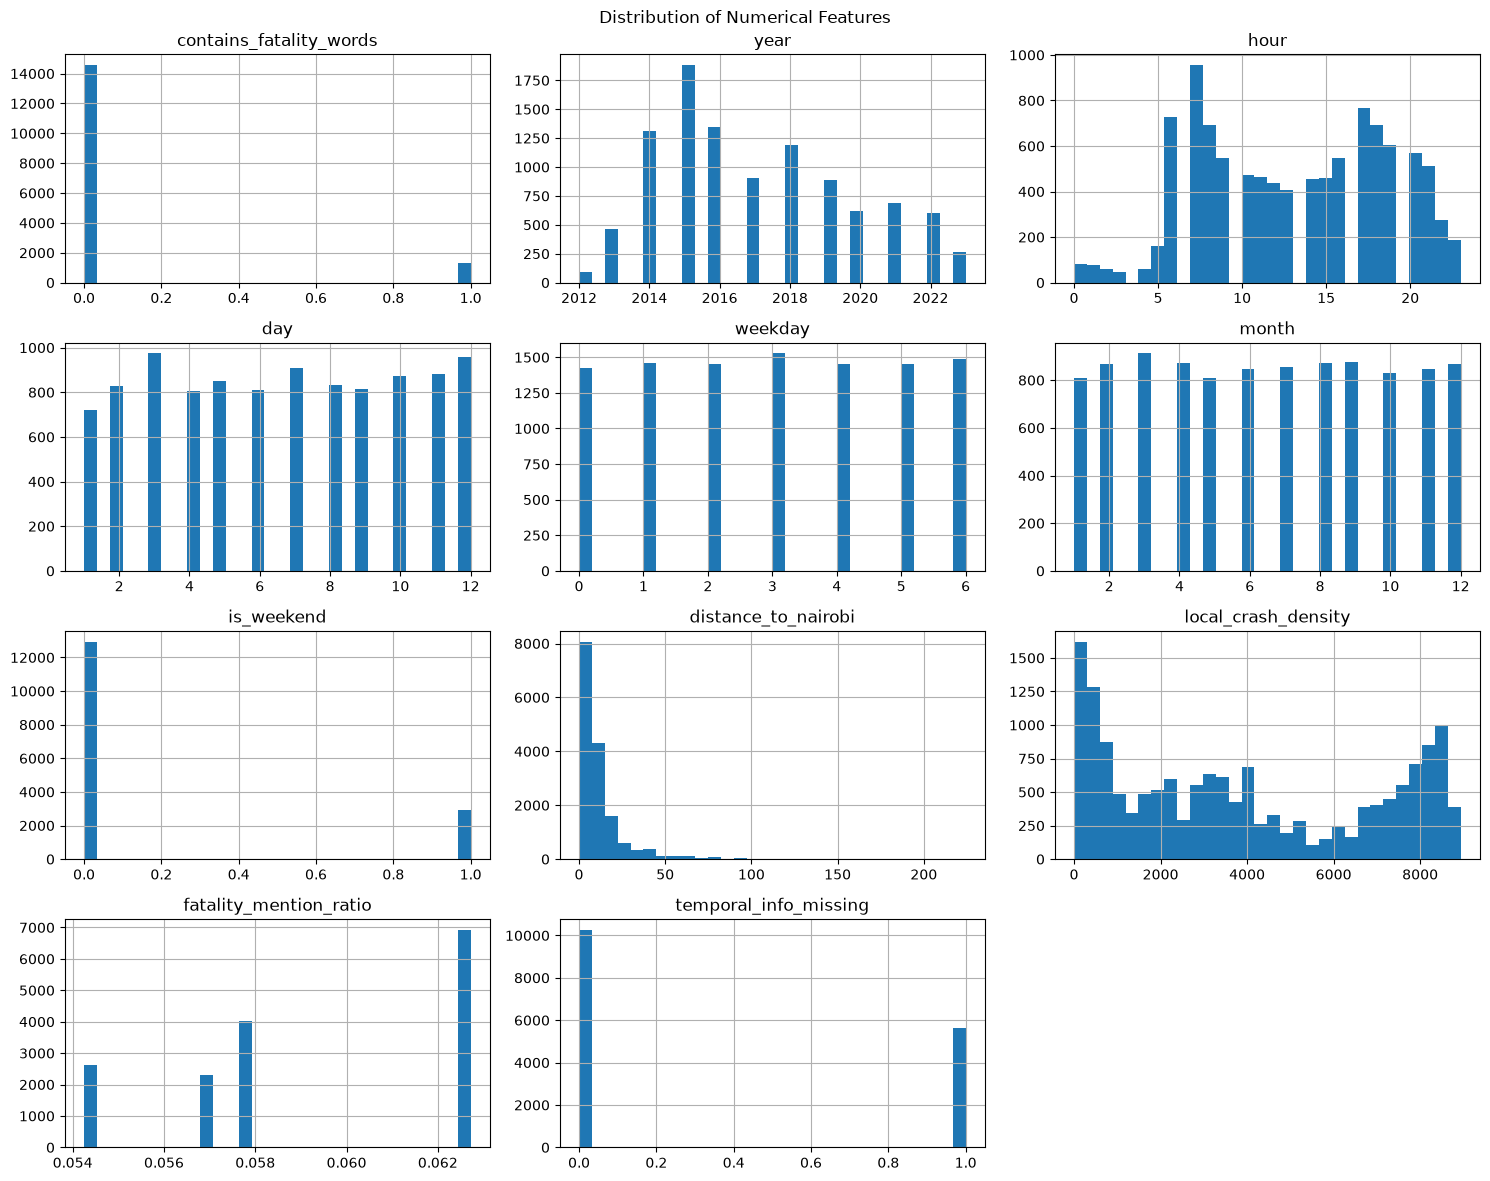

In [71]:
# Plot histograms to see the distributions of the numerical features.

numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.drop("severity_index")

df[numerical_columns].hist(
    figsize=(15, 12),
    bins=30
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

### Correlation Between Numerical Features

The heatmap shows how strongly numerical features are related to one another.

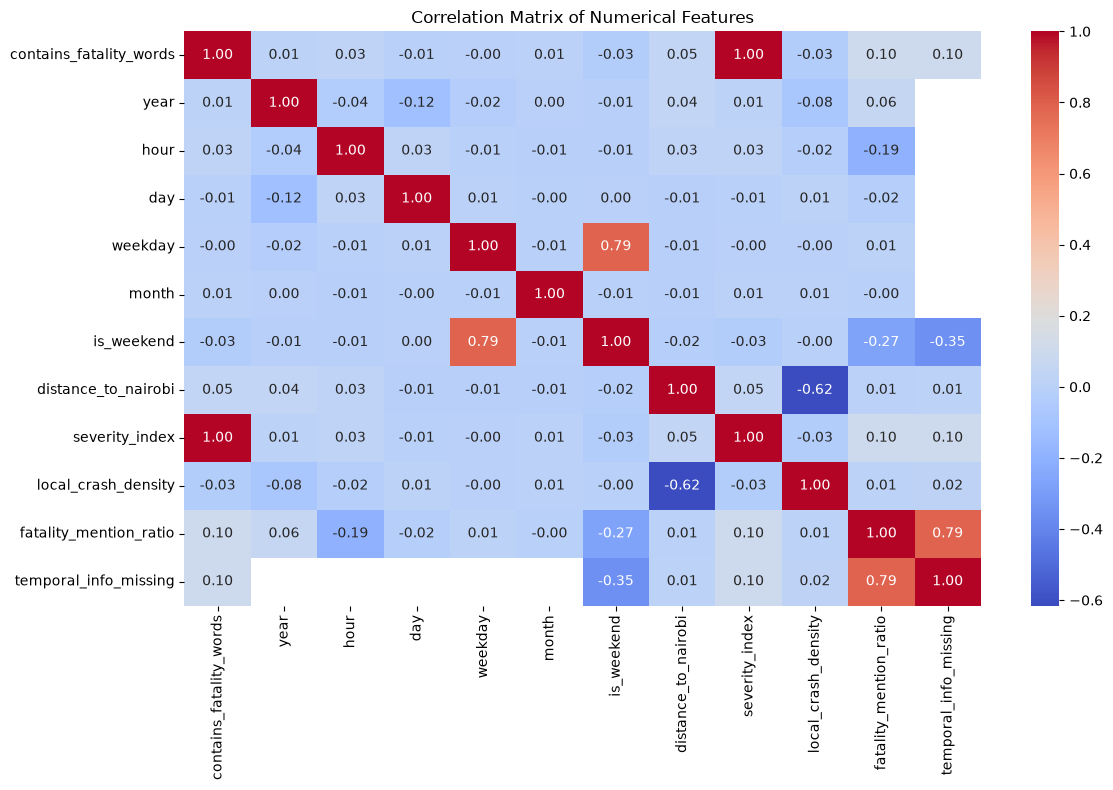

In [72]:
# Calculate and visualize correlations between numerical columns.

correlation_matrix = df.select_dtypes(
    include=["int64", "float64"]
).corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

## 4. Preparing Data for Machine Learning

Prepare a separate modelling dataset and remove columns that should not be used as model inputs.

In [73]:
# Make a modelling copy, then remove columns identified as leakage or redundant features.

# Make a copy of the cleaned dataset
model_df = df.copy()

# Remove features that could cause data leakage
leakage_columns = [
    "contains_fatality_words",
    "fatality_mention_ratio"
]

# Remove redundant or questionable features
redundant_columns = [
    "day_of_week",
    "is_weekend",
    "day"
]

model_df.drop(
    columns=leakage_columns + redundant_columns,
    inplace=True,
    errors="ignore"
)

print("Dataset shape:", model_df.shape)
print("\nRemaining features:")
print(model_df.columns.tolist())

print("\nMissing values:")
print(model_df.isnull().sum())


Dataset shape: (15878, 10)

Remaining features:
['year', 'hour', 'weekday', 'month', 'day_part', 'distance_to_nairobi', 'severity_index', 'local_crash_density', 'season', 'temporal_info_missing']

Missing values:
year                     5619
hour                     5619
weekday                  5619
month                    5619
day_part                    0
distance_to_nairobi         0
severity_index              0
local_crash_density         0
season                      0
temporal_info_missing       0
dtype: int64


### Separating Features and Target

X contains the information used for prediction, while y contains the crash severity we want to predict.

In [74]:
# Separate the input features (X) from the target variable (y), which is crash severity.

# Define the target variable
X = model_df.drop(columns=["severity_index"])

# Define the target
y = model_df["severity_index"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())


Features shape: (15878, 9)
Target shape: (15878,)

Target distribution:
severity_index
0    14563
1     1315
Name: count, dtype: int64


### Identifying Feature Types

The preprocessing steps differ depending on whether a feature is numerical or categorical.

In [75]:
# Import preprocessing tools and identify which input columns are numerical or categorical.

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)


Numerical features: ['year', 'hour', 'weekday', 'month', 'distance_to_nairobi', 'local_crash_density', 'temporal_info_missing']

Categorical features: ['day_part', 'season']


### Splitting the Dataset

Use most records for training and keep a separate portion for testing the models.

In [76]:
# Split the data into training and testing sets while preserving the class proportions.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))


Training set: (12702, 9)
Testing set: (3176, 9)

Training target distribution:
severity_index
0    0.917178
1    0.082822
Name: proportion, dtype: float64

Testing target distribution:
severity_index
0    0.917191
1    0.082809
Name: proportion, dtype: float64


### Setting Up Data Preprocessing

Missing values are filled, numerical features are scaled, and categorical features are converted into numeric form.

In [77]:
# Set up preprocessing: fill missing numerical values and scale them; fill and encode categories.

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


## 5. Model Development

Train different classification algorithms and compare how well they predict crash severity.

# Model Development

### Training the Classification Models

Train Logistic Regression, Decision Tree, and Random Forest models using the same preprocessing pipeline.

In [78]:
# Define three classification algorithms, then train each one using the same preprocessing steps.

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Define the models
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=10,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        max_depth=15,
        min_samples_split=10,
        random_state=42,
        n_jobs=-1
    )
}

# Store trained pipelines
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} trained successfully.")


Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.


## 6. Model Evaluation

Evaluate each trained model on the test data using several performance measures.

In [79]:
# Predict the test-set classes and calculate evaluation metrics for each trained model.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

results = []

for name, pipeline in trained_models.items():

    # Generate predictions
    y_pred = pipeline.predict(X_test)

    # Get probabilities for class 1
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

results_df


,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC
0,Logistic Regression,0.576826,0.113653,0.604563,0.191336,0.120578
2,Random Forest,0.716625,0.121284,0.387833,0.184783,0.108667
1,Decision Tree,0.550378,0.099105,0.547529,0.167832,0.095237


### Confusion Matrices

A confusion matrix shows how many predictions were correct and where the model confused the classes.

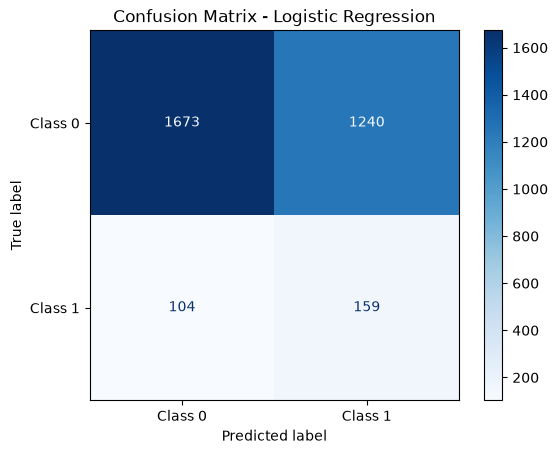

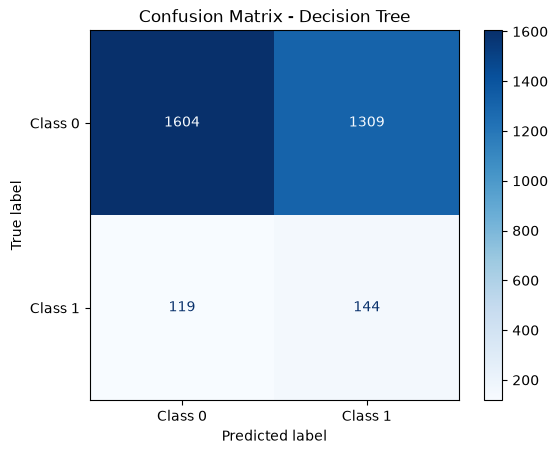

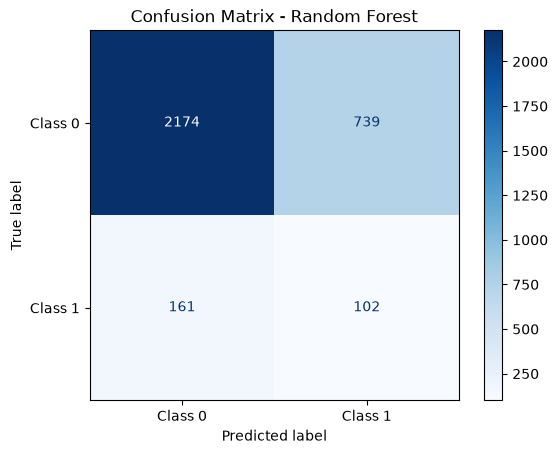

In [80]:
# Display a confusion matrix for each model to compare correct and incorrect predictions.

from sklearn.metrics import ConfusionMatrixDisplay

for name, pipeline in trained_models.items():

    y_pred = pipeline.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Class 0", "Class 1"],
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.show()


### Classification Reports

Review precision, recall, F1-score, and the confusion matrix for each model.

In [81]:
# Print precision, recall, F1-score and confusion-matrix values for each model.

from sklearn.metrics import classification_report, confusion_matrix

for name, pipeline in trained_models.items():

    y_pred = pipeline.predict(X_test)

    print(f"\n{'='*50}")
    print(name)
    print('='*50)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["Class 0", "Class 1"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))



Logistic Regression
              precision    recall  f1-score   support

     Class 0       0.94      0.57      0.71      2913
     Class 1       0.11      0.60      0.19       263

    accuracy                           0.58      3176
   macro avg       0.53      0.59      0.45      3176
weighted avg       0.87      0.58      0.67      3176

Confusion Matrix:
[[1673 1240]
 [ 104  159]]

Decision Tree
              precision    recall  f1-score   support

     Class 0       0.93      0.55      0.69      2913
     Class 1       0.10      0.55      0.17       263

    accuracy                           0.55      3176
   macro avg       0.52      0.55      0.43      3176
weighted avg       0.86      0.55      0.65      3176

Confusion Matrix:
[[1604 1309]
 [ 119  144]]

Random Forest
              precision    recall  f1-score   support

     Class 0       0.93      0.75      0.83      2913
     Class 1       0.12      0.39      0.18       263

    accuracy                           0.

### Baseline Model Comparison

A Dummy Classifier provides a simple baseline. More advanced models should be assessed against it.

In [82]:
# Train a simple baseline that always predicts the most common class, then evaluate it.

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

dummy_predictions = dummy.predict(X_test)
dummy_probabilities = dummy.predict_proba(X_test)[:, 1]

print("Dummy Classifier Results")
print("------------------------")
print("Accuracy:", accuracy_score(y_test, dummy_predictions))
print("Precision:", precision_score(y_test, dummy_predictions, zero_division=0))
print("Recall:", recall_score(y_test, dummy_predictions, zero_division=0))
print("F1 Score:", f1_score(y_test, dummy_predictions, zero_division=0))
print("PR-AUC:", average_precision_score(y_test, dummy_probabilities))


Dummy Classifier Results
------------------------
Accuracy: 0.917191435768262
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
PR-AUC: 0.08280856423173803


# Model Evaluation and Comparison
Three machine learning algorithms were trained and evaluated: Logistic Regression, Decision Tree and Random Forest.

The models were compared using accuracy, precision, recall, F1-score and PR-AUC. Since the dataset contains significantly more records in Class 0 than Class 1, accuracy alone was not used to determine the best-performing model.

## Final Model Evaluation

Based on the model comparison, Logistic Regression was selected as the final model because it achieved the highest F1-score (0.191) and recall (0.605) for Class 1.

The model achieved an overall accuracy of 57.68%, with a precision of 11.37% and a recall of 60.46% for Class 1.

The confusion matrix showed that the model correctly identified 159 Class 1 cases but missed 104. However, it also incorrectly classified 1,240 Class 0 cases as Class 1.

These results indicate that the model identifies a reasonable proportion of Class 1 cases but produces many false positives. Therefore, its predictions should be interpreted with caution.

## Conclusion

This project aimed to develop a machine learning model for predicting road crash severity using historical crash-related data.

The project involved data understanding, data cleaning, exploratory data analysis, feature engineering, model preparation, training and evaluation.

Three classification algorithms were tested: Logistic Regression, Decision Tree and Random Forest. Logistic Regression performed best in terms of Class 1 recall and F1-score, making it the preferred model among the three.

However, the results show that the model still has limitations, particularly its low precision and high number of false positive predictions.

The project demonstrates the potential of machine learning in analysing road crash data and supporting efforts to understand crash patterns. Further improvements are necessary before the model can be considered reliable for practical use.

## Recommendations

Based on the findings and limitations of this project, the following recommendations are proposed:

1. **Improve data quality:** Collect more complete and accurate crash records, particularly for records with missing temporal information.

2. **Use more relevant features:** Include additional factors such as road conditions, weather conditions, vehicle types, traffic volume and driver-related information where available.

3. **Address class imbalance:** Explore techniques such as SMOTE and other class-balancing methods to improve the model's ability to identify minority-class cases.

4. **Improve model performance:** Experiment with additional algorithms and hyperparameter tuning to improve prediction accuracy, precision and recall.

5. **Use reliable crash records:** Verify that the target severity labels represent actual crash outcomes and are not derived from the same information used as input features.

6. **Further testing:** Evaluate the model using additional and more recent crash data before considering real-world implementation.